# Validation 3 — Thứ tự EASE có ổn định theo thời gian? (60 mã)

**Hai cách cắt:** (1) cửa sổ trượt 750 phiên (~3 năm), bước 21 phiên, $k = \lfloor 750^{0,4}\rfloor = 14$; (2) bốn giai đoạn cố định.
Với mỗi lát cắt: vị trí của từng mã trong thứ tự EASE, $\overline{\hat\Psi}$, và hệ số tải $\hat\beta_i$ (leave-one-out) trong lát cắt đó.

## 0. Thiết lập

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as U
import causal_tail as CT
import causal_baselines as CB
import tail_preprocessing as TP

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.3f}".format)
SYMBOLS, COL, PAL = U.SYMBOLS, U.SYMBOL_COLORS, U.PALETTE
FOLDER = "validation"                      # hình → report/figure/processing, bảng → report/table/processing
METHOD_COLORS = {"EASE": PAL["blue_main"], "Pairwise LiNGAM": PAL["red_strong"], "ICA-LiNGAM": PAL["green_3"],
                 "Rank PC": PAL["violet"], "Ngẫu nhiên": PAL["neutral"]}

import validation as V
from scipy import stats
P = len(SYMBOLS)
OFF = ~np.eye(P, dtype=bool)

Z = pd.read_parquet(ROOT / "data" / "processed" / "garch_std_resid_market.parquet")
z = Z[SYMBOLS]
n, K = len(z), CT.default_k(len(z))
E, beta = V.loo_market_adjust(z)                 # phần dư sau khi loại thị trường leave-one-out
print(f"n = {n} phiên ({Z.index[0]:%d/%m/%Y} → {Z.index[-1]:%d/%m/%Y}), {P} mã, k = {K}")

WINDOW, STEP = 750, 21
PERIODS = {"2018-06 → 2019-12 (trước COVID)": ("2018-06-01", "2019-12-31"),
           "2020-01 → 2021-12 (COVID, bùng nổ)": ("2020-01-01", "2021-12-31"),
           "2022-01 → 2023-12 (khủng hoảng BĐS)": ("2022-01-01", "2023-12-31"),
           "2024-01 → 2026-11 (gần đây)": ("2024-01-01", "2026-11-30")}

n = 2103 phiên (05/06/2018 → 25/11/2026), 60 mã, k = 21


## 1. Cửa sổ trượt

**Tính gì:** cho mỗi cửa sổ: vị trí EASE của từng mã (heatmap thời gian × mã, xanh đậm = gần gốc), $\overline{\hat\Psi}$, và mã có $\hat\beta$ thấp nhất.

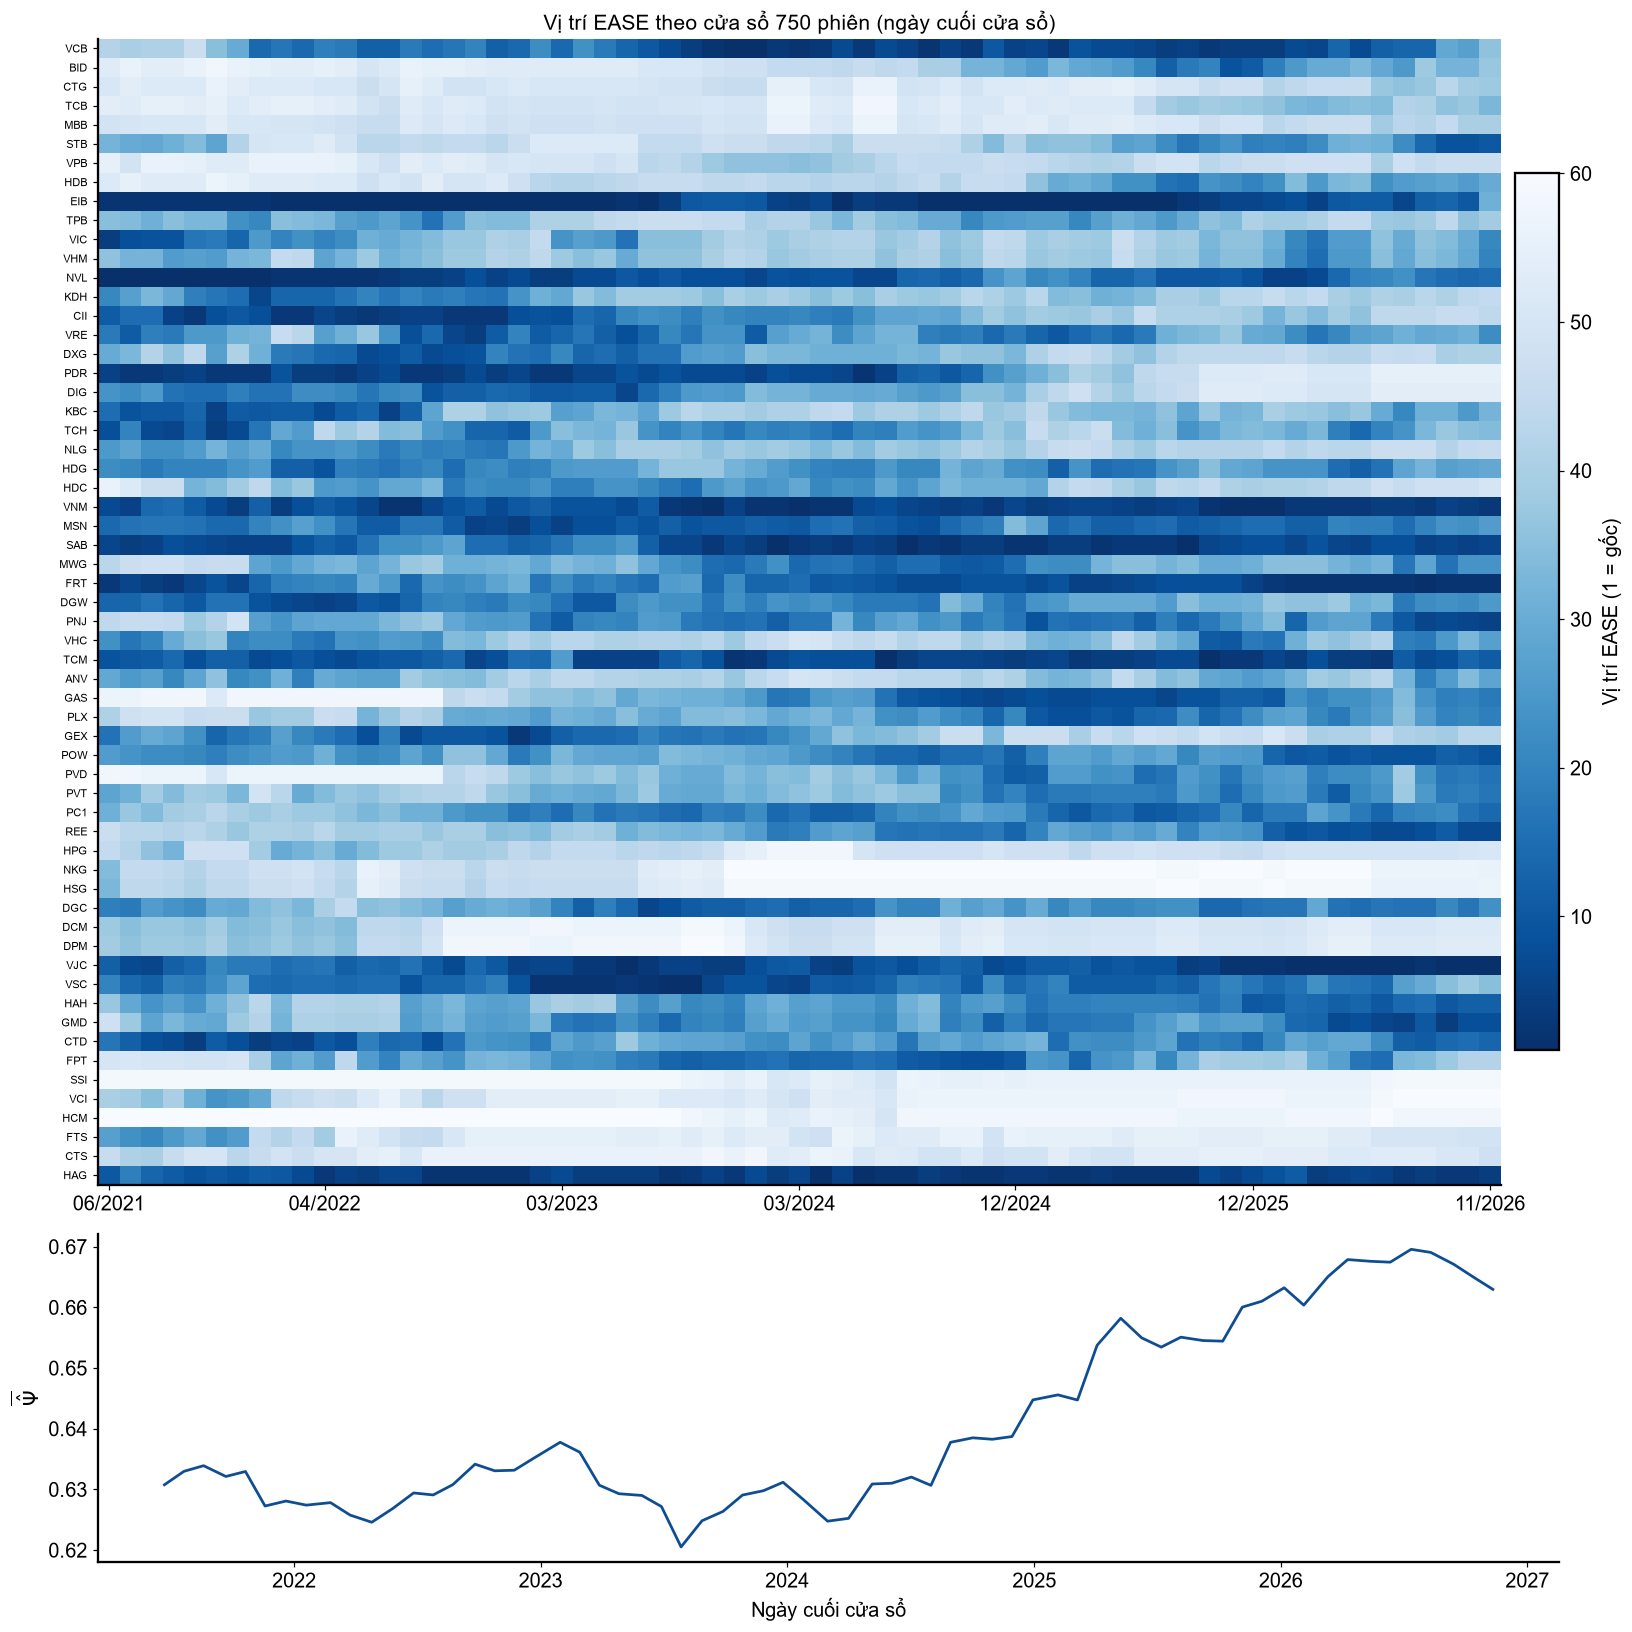

65 cửa sổ. Gốc = mã β thấp nhất: 29%; gốc thuộc 3 mã β thấp nhất: 54%
Spearman trung bình giữa vị trí EASE và β trong từng cửa sổ: 0.71


,ty_le_lam_goc,vi_tri_TB
EIB,0.460,4.030
HAG,0.030,4.920
VNM,0.080,5.570
TCM,0.030,7.650
VJC,0.150,7.860
SAB,0.050,8.090
NVL,0.120,9.200
FRT,0.020,11.580
VCB,0.030,13.430
VSC,0.030,14.400


In [2]:
roll = V.rolling_ease(z, window=WINDOW, step=STEP)
betas = [V.loo_market_adjust(z.loc[:end].iloc[-WINDOW:])[1] for end in roll.index]
roll_beta = pd.DataFrame(betas, index=roll.index)
U.save_table(roll.join(roll_beta.add_prefix("beta_")), "03_rolling_ease", FOLDER)
pos = roll.filter(like="pos_").rename(columns=lambda c: c[4:])[SYMBOLS]

fig, axes = plt.subplots(2, 1, figsize=(15, 15), sharex=False, gridspec_kw={"height_ratios": [3.5, 1]})
im = axes[0].imshow(pos.T.values, aspect="auto", cmap="Blues_r", vmin=1, vmax=P, interpolation="nearest")
axes[0].set_yticks(range(P), SYMBOLS, fontsize=7)
tick = np.linspace(0, len(pos) - 1, 7).astype(int)
axes[0].set_xticks(tick, [pos.index[i].strftime("%m/%Y") for i in tick])
cb = fig.colorbar(im, ax=axes[0], fraction=0.03, pad=0.01); cb.set_label("Vị trí EASE (1 = gốc)")
axes[0].set_title("Vị trí EASE theo cửa sổ 750 phiên (ngày cuối cửa sổ)")
axes[1].plot(roll.index, roll.coef_mean, color=PAL["blue_main"], lw=1.8)
axes[1].set_ylabel(r"$\overline{\hat\Psi}$"); axes[1].set_xlabel("Ngày cuối cửa sổ")
U.finalize_figure(fig, "03_rolling_ease", folder=FOLDER); plt.show()

root = pos.idxmin(axis=1); low_beta = roll_beta.idxmin(axis=1)
low3 = roll_beta.apply(lambda r_: set(r_.nsmallest(3).index), axis=1)
summary = pd.DataFrame({"ty_le_lam_goc": root.value_counts(normalize=True),
                        "vi_tri_TB": pos.mean()}).reindex(SYMBOLS).fillna(0).sort_values("vi_tri_TB")
print(f"{len(roll)} cửa sổ. Gốc = mã β thấp nhất: {(root == low_beta).mean():.0%}; gốc thuộc 3 mã β thấp nhất: "
      f"{np.mean([r_ in s_ for r_, s_ in zip(root, low3)]):.0%}")
print("Spearman trung bình giữa vị trí EASE và β trong từng cửa sổ:",
      round(float(np.mean([stats.spearmanr(pos.loc[t], roll_beta.loc[t])[0] for t in pos.index])), 2))
summary.round(2)

### Phân tích
- Trong 65 cửa sổ 3 năm: gốc là **EIB 46%, VJC 15%, NVL 12%, VNM 8%** — luôn là mã ít nhạy thị trường; theo vị trí trung bình, nhóm cuối là **chứng khoán** (HCM 58,3, SSI 57,1, CTS, VCI),
  **thép** (NKG, HSG), phân bón (DPM, DCM) và ngân hàng lớn (CTG, MBB, TCB, VPB: 47–50).
- **Gốc trùng mã có $\hat\beta$ thấp nhất ở 29% cửa sổ và thuộc 3 mã $\hat\beta$ thấp nhất ở 54%; Spearman trung bình giữa vị trí EASE và $\hat\beta$ trong từng
  cửa sổ = 0,71** (20 mã: 59%, 86%, 0,78). Quan hệ "thứ tự EASE ≈ thứ tự tải" lặp lại qua thời gian, yếu đi vì phụ thuộc trong ngành hẹp cũng kéo mã về cuối.

## 2. Theo giai đoạn

**Tính gì:** thứ tự EASE, $\overline{\hat\Psi}$, Spearman giữa vị trí EASE và $\hat\beta$ trong từng giai đoạn (389–720 phiên, $k$ = 10–13).

In [3]:
rows = []
for name, (a, b) in PERIODS.items():
    W = z.loc[a:b]; kk = CT.default_k(len(W))
    M = CT.tail_coef_matrix(W, k=kk); o = CT.ease(M)
    bW = V.loo_market_adjust(W)[1]
    rows.append({"giai_doan": name, "n": len(W), "k": kk, "Psi_TB": M.values[OFF].mean(),
                 "rho_vitri_beta": stats.spearmanr([o.index(s) + 1 for s in SYMBOLS], bW.loc[SYMBOLS])[0],
                 "5_goc": " → ".join(o[:5]), "3_cuoi": " → ".join(o[-3:])})
per = pd.DataFrame(rows).set_index("giai_doan")
U.save_table(per, "03_period_ease", FOLDER)
pd.set_option("display.max_colwidth", 60)
per.round(3)

,n,k,Psi_TB,rho_vitri_beta,5_goc,3_cuoi
giai_doan,,,,,,
2018-06 → 2019-12 (trước COVID),389,10,0.580,0.719,NVL → VIC → PDR → VHC → EIB,PLX → MBB → HDB
"2020-01 → 2021-12 (COVID, bùng nổ)",496,11,0.644,0.718,NVL → PDR → EIB → TCM → KBC,DPM → HCM → SSI
2022-01 → 2023-12 (khủng hoảng BĐS),498,11,0.633,0.677,EIB → VNM → SAB → VCB → GAS,FTS → HSG → NKG
2024-01 → 2026-11 (gần đây),720,13,0.664,0.811,FRT → VJC → VNM → PNJ → GMD,HCM → SSI → VCI


### Phân tích
- 5 mã đầu đổi theo giai đoạn nhưng luôn là mã ít nhạy thị trường (NVL, PDR, EIB, VNM, SAB, VJC, FRT); 3 mã cuối luôn thuộc ngân hàng, chứng khoán hoặc thép
  (MBB, HDB → HCM, SSI → HSG, NKG → SSI, VCI).
- Spearman giữa vị trí EASE và $\hat\beta$ trong từng giai đoạn: 0,72 · 0,72 · 0,68 · 0,81 — mạnh ở mọi giai đoạn.
- $\overline{\hat\Psi}$: 0,58 (2018–2019) → 0,64 (COVID) → 0,63 (khủng hoảng BĐS) → 0,66 (gần đây).

## 3. Kết luận
1. Cấu trúc "ít nhạy thị trường trước, chứng khoán/ngân hàng/thép sau" **ổn định qua mọi cửa sổ và giai đoạn**; thứ tự chi tiết thì không.
2. Thứ tự EASE đi theo hệ số tải thị trường ở mọi lát cắt thời gian (ρ trung bình 0,71; 0,68–0,81 theo giai đoạn).